# Wheat Seeds Classification Using Kernel SVM

## Optimization Algorithms Comparison

### Objective

This notebook compares five optimization algorithms
used to train a multiclass SVM with a Linear Kernel.

### Optimization Algorithms

- Gradient Descent
- Stochastic Gradient Descent
- Mini-Batch Gradient Descent
- Adam
- RMSprop

### Comparison Criteria

- Classification Performance
- Convergence Behavior
- Training Efficiency
- Computational Cost

In [1]:
import os

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

/kaggle/input/datasets/hadeelraed6/svm-optimizer-results/Adam_results.csv
/kaggle/input/datasets/hadeelraed6/svm-optimizer-results/GD_results.csv
/kaggle/input/datasets/hadeelraed6/svm-optimizer-results/MiniBatchGD_results.csv
/kaggle/input/datasets/hadeelraed6/svm-optimizer-results/RMSprop_results.csv
/kaggle/input/datasets/hadeelraed6/svm-optimizer-results/SGD_results.csv


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

In [3]:
files = [
    "GD_results.csv",
    "SGD_results.csv",
    "MiniBatchGD_results.csv",
    "Adam_results.csv",
    "RMSprop_results.csv"
]

file_paths = {}

for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename in files:
            file_paths[filename] = os.path.join(
                dirname, filename
            )

missing = set(files) - set(file_paths)

assert not missing, f"Missing files: {missing}"

results = pd.concat(
    [pd.read_csv(file_paths[file]) for file in files],
    ignore_index=True
)

display(results.round(4))

,Optimizer,Kernel,Lambda,Epochs,Learning Rate,Batch Size,Total Updates,Train Accuracy,Validation Accuracy,Accuracy,Precision,Recall,F1-Score,Training Time,Final Train Loss,Final Validation Loss,Test Loss,Beta 1,Beta 2,Epsilon
0,Gradient Descent,Linear,0.01,200,0.001,147,200,0.9184,0.8387,0.8750,0.8750,0.8697,0.8680,0.5346,0.3032,0.3715,0.4366,NaN,NaN,NaN
1,Stochastic Gradient Descent,Linear,0.01,200,0.001,1,29400,0.9320,0.8710,0.8750,0.8750,0.8697,0.8680,22.6964,0.1945,0.2427,0.3082,NaN,NaN,NaN
2,Mini-Batch Gradient Descent,Linear,0.01,200,0.001,16,2000,0.9116,0.8387,0.8750,0.8750,0.8697,0.8680,2.1085,0.3031,0.3826,0.4292,NaN,NaN,NaN
3,Adam,Linear,0.01,200,0.001,16,2000,0.9388,0.9355,0.8750,0.8750,0.8697,0.8680,2.3437,0.1745,0.2122,0.2755,0.9,0.999,0.0
4,RMSprop,Linear,0.01,200,0.001,16,2000,0.9116,0.9032,0.9062,0.9049,0.9030,0.9026,2.0673,0.2574,0.3022,0.3326,NaN,NaN,NaN


In [4]:
performance = results[[
    "Optimizer",
    "Train Accuracy",
    "Validation Accuracy",
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]]

display(
    performance.style
    .format(precision=4, subset=performance.columns[1:])
    .highlight_max(
        subset=performance.columns[1:],
        color="lightgreen"
    )
)

,Optimizer,Train Accuracy,Validation Accuracy,Accuracy,Precision,Recall,F1-Score
0,Gradient Descent,0.9184,0.8387,0.8750,0.8750,0.8697,0.8680
1,Stochastic Gradient Descent,0.9320,0.8710,0.8750,0.8750,0.8697,0.8680
2,Mini-Batch Gradient Descent,0.9116,0.8387,0.8750,0.8750,0.8697,0.8680
3,Adam,0.9388,0.9355,0.8750,0.8750,0.8697,0.8680
4,RMSprop,0.9116,0.9032,0.9062,0.9049,0.9030,0.9026


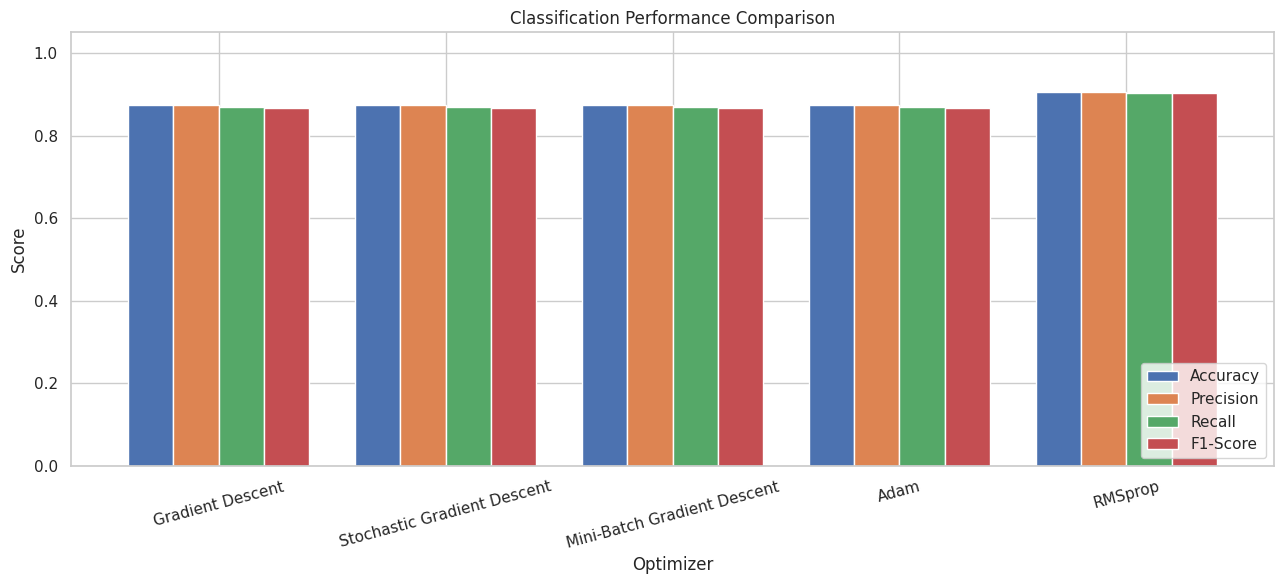

In [5]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

results.set_index("Optimizer")[metrics].plot(
    kind="bar",
    figsize=(13, 6),
    width=0.8
)

plt.title("Classification Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Optimizer")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

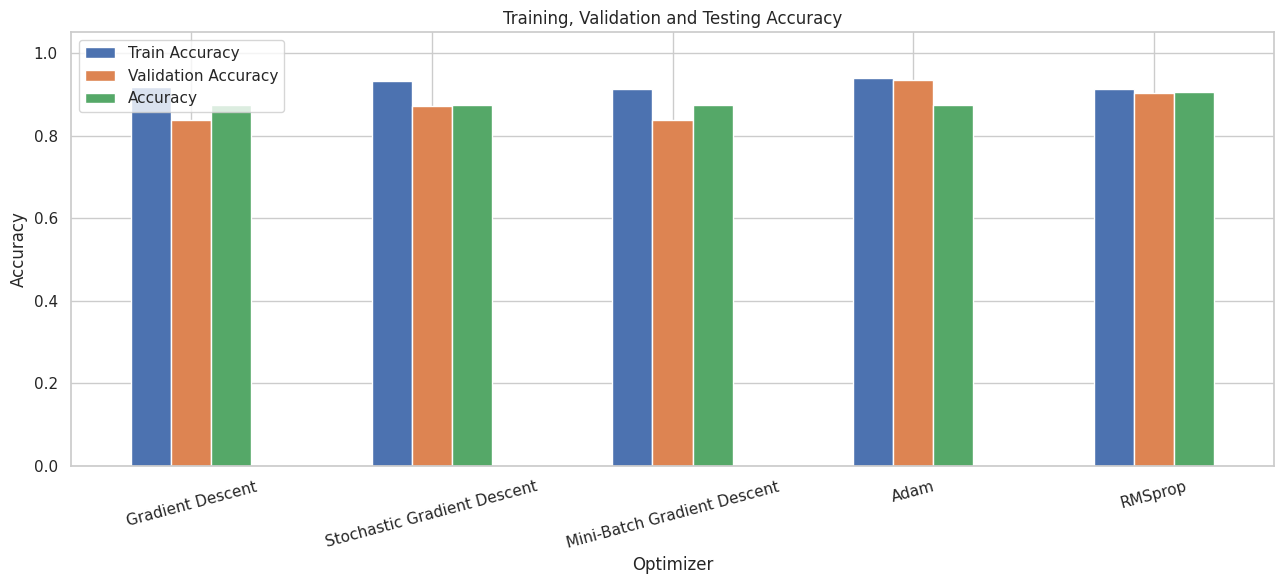

In [6]:
accuracy_columns = [
    "Train Accuracy",
    "Validation Accuracy",
    "Accuracy"
]

results.set_index("Optimizer")[accuracy_columns].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Training, Validation and Testing Accuracy")
plt.ylabel("Accuracy")
plt.ylim(0, 1.05)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

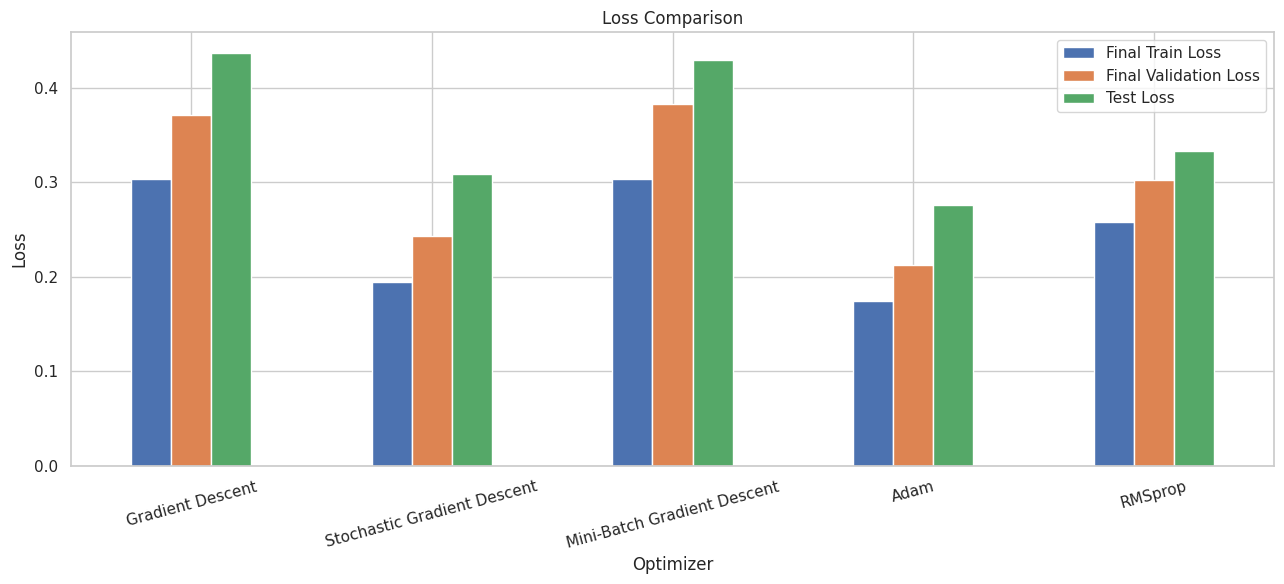

In [7]:
loss_columns = [
    "Final Train Loss",
    "Final Validation Loss",
    "Test Loss"
]

results.set_index("Optimizer")[loss_columns].plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Loss Comparison")
plt.ylabel("Loss")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

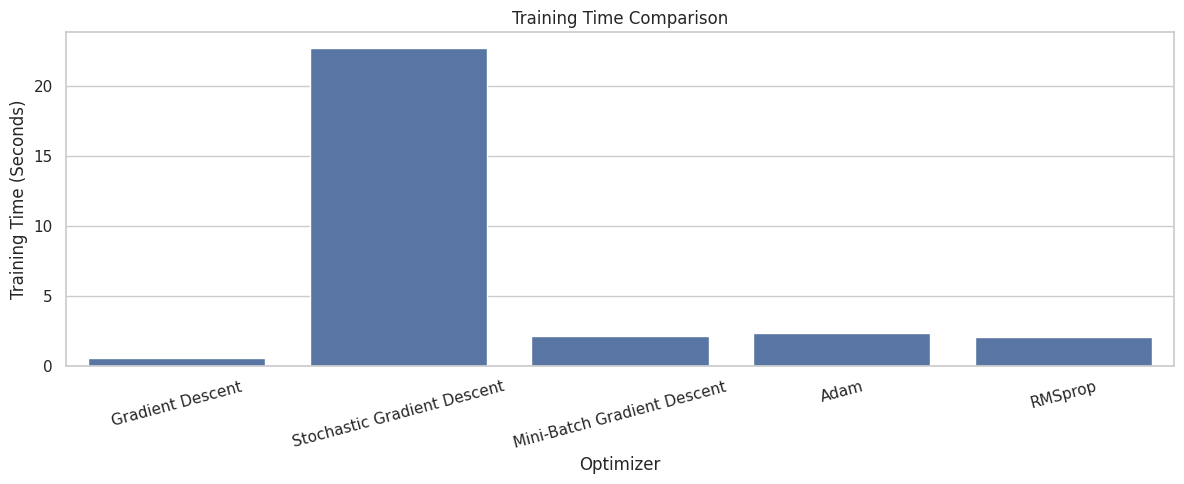

In [8]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=results,
    x="Optimizer",
    y="Training Time"
)

plt.title("Training Time Comparison")
plt.ylabel("Training Time (Seconds)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

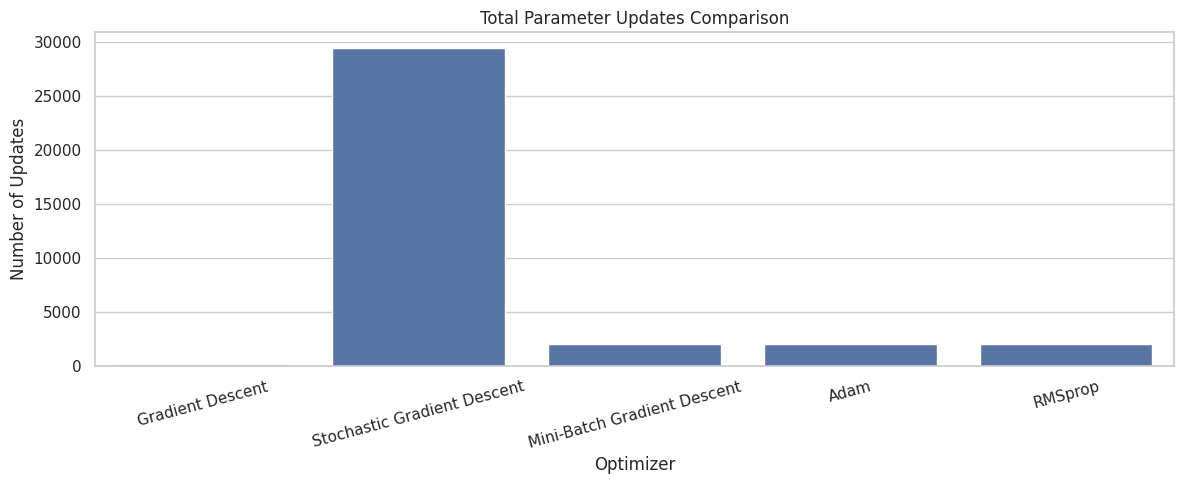

In [9]:
plt.figure(figsize=(12, 5))

sns.barplot(
    data=results,
    x="Optimizer",
    y="Total Updates"
)

plt.title("Total Parameter Updates Comparison")
plt.ylabel("Number of Updates")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [10]:
criteria = {
    "Best Test Accuracy": ("Accuracy", "max"),
    "Best Validation Accuracy": ("Validation Accuracy", "max"),
    "Best Precision": ("Precision", "max"),
    "Best Recall": ("Recall", "max"),
    "Best F1-Score": ("F1-Score", "max"),
    "Lowest Training Loss": ("Final Train Loss", "min"),
    "Lowest Validation Loss": ("Final Validation Loss", "min"),
    "Lowest Test Loss": ("Test Loss", "min"),
    "Fastest Training": ("Training Time", "min"),
    "Fewest Updates": ("Total Updates", "min")
}

summary = []

for criterion, (column, direction) in criteria.items():

    value = (
        results[column].max()
        if direction == "max"
        else results[column].min()
    )

    winners = results.loc[
        results[column] == value, "Optimizer"
    ]

    summary.append({
        "Criterion": criterion,
        "Best Optimizer": ", ".join(winners),
        "Value": value
    })

comparison_summary = pd.DataFrame(summary)

display(comparison_summary.round(4))

,Criterion,Best Optimizer,Value
0,Best Test Accuracy,RMSprop,0.9062
1,Best Validation Accuracy,Adam,0.9355
2,Best Precision,RMSprop,0.9049
3,Best Recall,RMSprop,0.9030
4,Best F1-Score,RMSprop,0.9026
5,Lowest Training Loss,Adam,0.1745
6,Lowest Validation Loss,Adam,0.2122
7,Lowest Test Loss,Adam,0.2755
8,Fastest Training,Gradient Descent,0.5346
9,Fewest Updates,Gradient Descent,200.0000


In [11]:
results.to_csv(
    "Final_Optimizers_Comparison.csv",
    index=False
)

comparison_summary.to_csv(
    "Best_Optimizers_Summary.csv",
    index=False
)

print("Results Saved Successfully")

Results Saved Successfully
